# Clothing defect check

Upload your own photo of a garment and see how the model classifies it: damaged, unsure or clean, which defect types, how confident it is, and where the damage is.

1. Select the **.venv** kernel (top right), then **Run All**.
2. Use the **Upload photos** button in cell 4. You can pick several photos at once.
3. Or put photos in `CV/demo_photos/` and run cell 5. If the upload cell shows no pictures in your editor, cell 5 always does (uploads are saved there too).

How it decides:
- **Damage detector** (YOLO11s, trained on our data plus defect-clothes-ukrks v3) classifies the photo: score ≥ 0.20 means *damaged*, 0.15–0.20 means *unsure*, below that means *clean*. Each defect type (hole, stain) gets its own score.
- **Locator** (YOLO11m, same training data) also votes: score ≥ 0.40 means *damaged*, 0.25–0.40 *unsure*. It also draws the boxes (regions ≥ 0.15). Only detections on the garment are kept.
- **Second opinion** (Grounding DINO, open-vocabulary): if both models say clean but it sees a likely hole or stain (≥ 0.50), the photo becomes *unsure* instead of clean. It never makes a photo *damaged* on its own.
- Red = hole, purple = stain. On photos larger than 1000 px, both models also look at a crop of the garment.

Phone photos work best as one full shot of the item plus one close-up of the damage, in good light. iPhone HEIC photos must be exported as JPEG first.

In [46]:
import sys
from pathlib import Path

CV_DIR = Path.cwd() if (Path.cwd() / "scripts" / "predict.py").exists() else Path.cwd() / "CV"
sys.path.insert(0, str(CV_DIR / "scripts"))
sys.path.insert(0, str(CV_DIR / ".pydeps"))  # transformers, for the Grounding DINO second opinion

import os
os.environ.setdefault("HF_HOME", str(CV_DIR / ".hf_cache"))  # Grounding DINO weights are cached here

import io
import cv2
import numpy as np
import ipywidgets as widgets
from IPython.display import Image as IPImage, display
from PIL import Image, ImageOps

import importlib
import predict

importlib.reload(predict)  # pick up changes to predict.py without restarting the kernel
from predict import DEFECTS, DefectPredictor, draw

# device="cpu" on a machine without an NVIDIA GPU; second_opinion=False skips Grounding DINO
predictor = DefectPredictor(device="0", second_opinion=True)
print("Damage detector:", predict.DEFAULT_DETECTOR.name, "| threshold", predictor.damage_conf)
print("Damage locator :", predict.DEFAULT_LOCATOR.name, "| damaged at", predictor.locator_damage_conf)
print("Second opinion :", "Grounding DINO" if predictor.gdino else "off")

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Damage detector: clothes_damage_detector.pt | threshold 0.2
Damage locator : clothes_damage_locator.pt | damaged at 0.4
Second opinion : Grounding DINO


In [47]:
import html

VERDICT_TEXT = {"damaged": "DAMAGED", "unsure": "UNSURE (needs a closer photo)", "clean": "CLEAN", "no_garment": "NO GARMENT FOUND"}


def bar(score, width=20):
    filled = round(score * width)
    return "█" * filled + "░" * (width - filled)


def analyze(img_bgr, name=""):
    """Classify one BGR image. Returns (summary text, marked-up photo as JPEG bytes, raw result)."""
    result = predictor.predict(img_bgr)
    lines = [f"── {name}",
             f"   Classification : {VERDICT_TEXT[result['verdict']]}",
             f"   Defect types   : {', '.join(result['defect_types']) or 'none'}"]
    for c in DEFECTS:
        s = result["class_scores"][c]
        mark = "  <- above threshold" if s >= predictor.damage_conf else ""
        lines.append(f"   {c:<6} score   : {bar(s)} {s:.2f}{mark}")
    so = result.get('second_opinion_score')
    lines.append(f"   Model scores   : detector {result['detector_score']:.2f} | locator {result['locator_score']:.2f}"
                 + (f" | second opinion {so:.2f}" if so else ""))
    lines.append(f"   Regions marked : {len(result['regions'])}   ({result['note']})")
    vis = draw(img_bgr, result)
    scale = 900 / max(vis.shape[:2])
    if scale < 1:
        vis = cv2.resize(vis, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    return "\n".join(lines), cv2.imencode(".jpg", vis)[1].tobytes(), result


def check(img_bgr, name=""):
    """Print the classification and show the marked-up photo as normal cell output."""
    text, jpg, result = analyze(img_bgr, name)
    print(text)
    display(Image.open(io.BytesIO(jpg)))  # a PIL image renders reliably in VS Code
    return result


def load_bytes(data: bytes):
    """Decode an uploaded file, applying the phone's EXIF rotation."""
    pil = ImageOps.exif_transpose(Image.open(io.BytesIO(data))).convert("RGB")
    return cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)

In [48]:
# Cell 4: upload photos. Results appear below the button.
# Uploads are also saved to CV/demo_photos/uploads, so cell 5 can show them again.
upload = widgets.FileUpload(accept="image/*", multiple=True, description="Upload photos")
results_box = widgets.VBox()
upload_dir = CV_DIR / "demo_photos" / "uploads"


def on_upload(change):
    files = change["new"]
    files = files.values() if isinstance(files, dict) else files  # ipywidgets 7 vs 8
    upload_dir.mkdir(parents=True, exist_ok=True)
    children = [widgets.HTML("<i>Checking photos…</i>")]
    results_box.children = children
    children = []
    for f in files:
        name = f.get("name") or f.get("metadata", {}).get("name", "photo.jpg")
        data = bytes(f["content"])
        (upload_dir / name).write_bytes(data)
        try:
            text, jpg, _ = analyze(load_bytes(data), name)
            children += [widgets.HTML(f"<pre>{html.escape(text)}</pre>"),
                         widgets.Image(value=jpg, format="jpeg", layout=widgets.Layout(max_width="700px"))]
        except Exception as exc:
            children.append(widgets.HTML(f"<pre>{html.escape(name)}: could not read this image ({html.escape(str(exc))}). Use JPEG or PNG.</pre>"))
    results_box.children = children


upload.observe(on_upload, names="value")
display(widgets.VBox([upload, results_box]))

── 02243bf5b1ab_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ██████████████░░░░░░ 0.70  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.23 | locator 0.70
   Regions marked : 1   (Damage found (1 region(s)).)


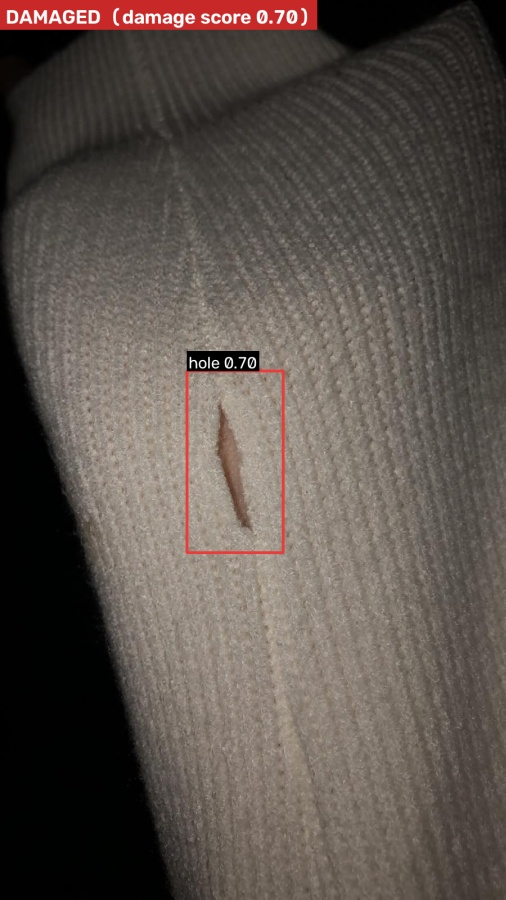

── 165be4578857_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : █████████░░░░░░░░░░░ 0.47  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.47 | locator 0.00
   Regions marked : 1   (Damage found (1 region(s)).)


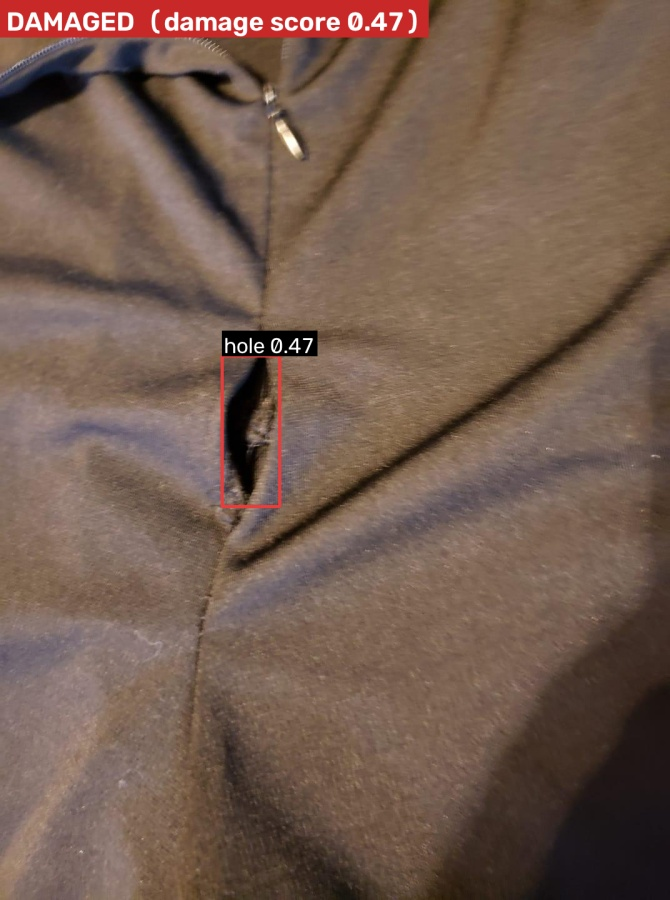

── 1b11a48c1068_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : █████████░░░░░░░░░░░ 0.43  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.43 | locator 0.00
   Regions marked : 1   (Damage found (1 region(s)).)


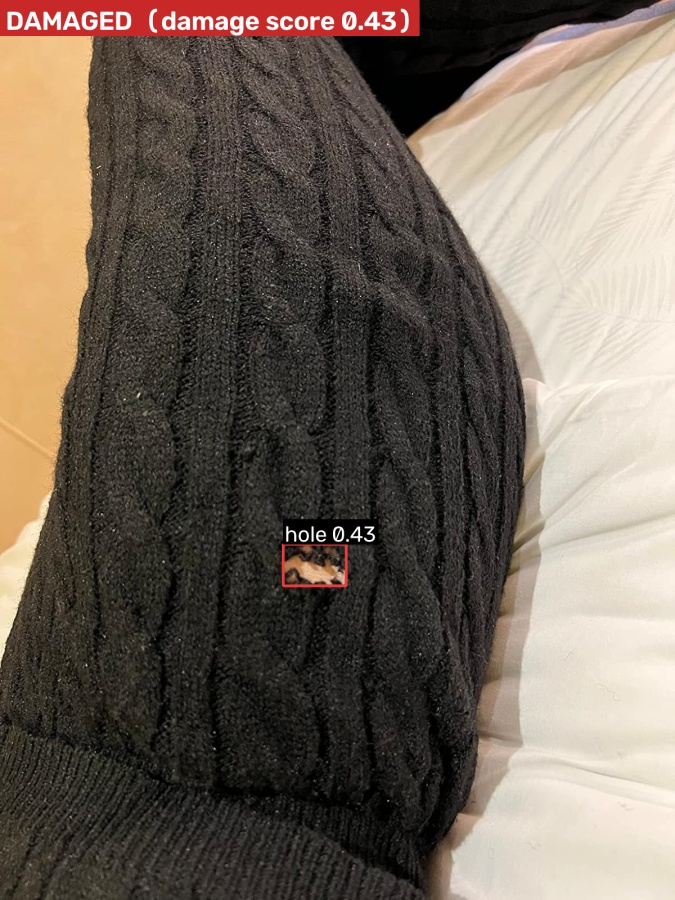

── 3850b77f8c48_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ███████████░░░░░░░░░ 0.55  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.17 | locator 0.55
   Regions marked : 1   (Damage found (1 region(s)).)


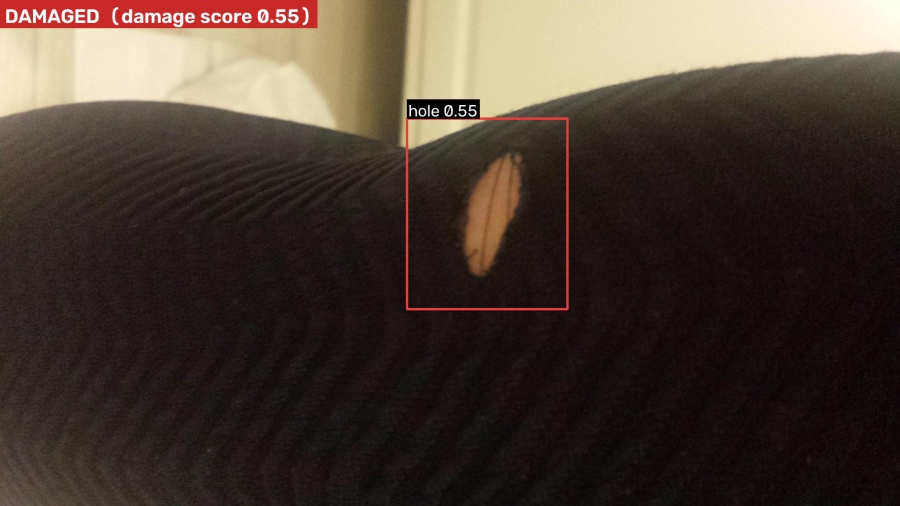

── 4158e700e019_1.jpg
   Classification : CLEAN
   Defect types   : none
   hole   score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.00 | locator 0.00
   Regions marked : 0   (No hole or stain found on the garment.)


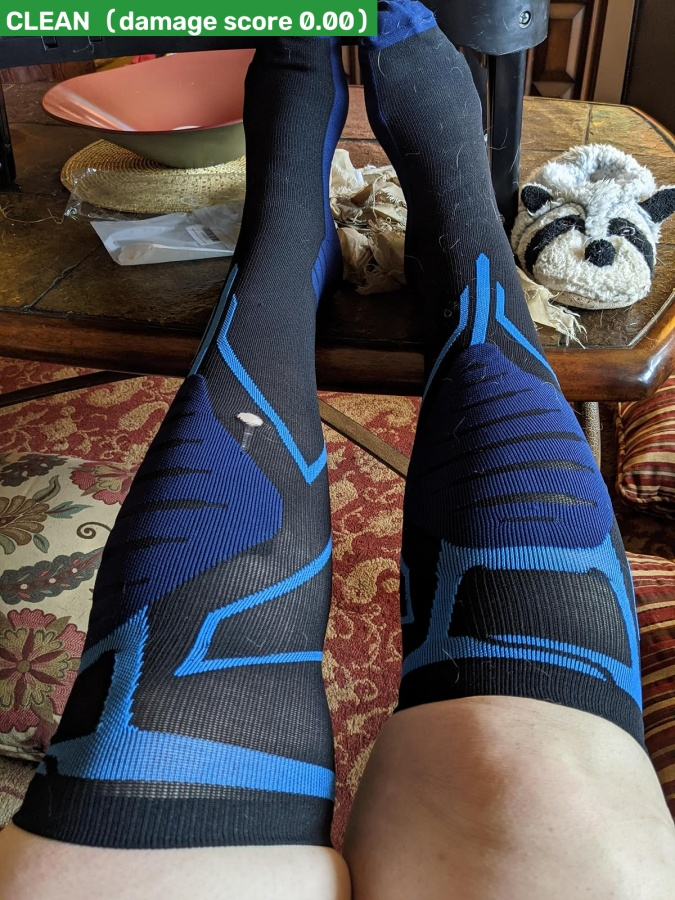

── 5289a73108c9_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ██████████░░░░░░░░░░ 0.50  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.17 | locator 0.50
   Regions marked : 1   (Damage found (1 region(s)).)


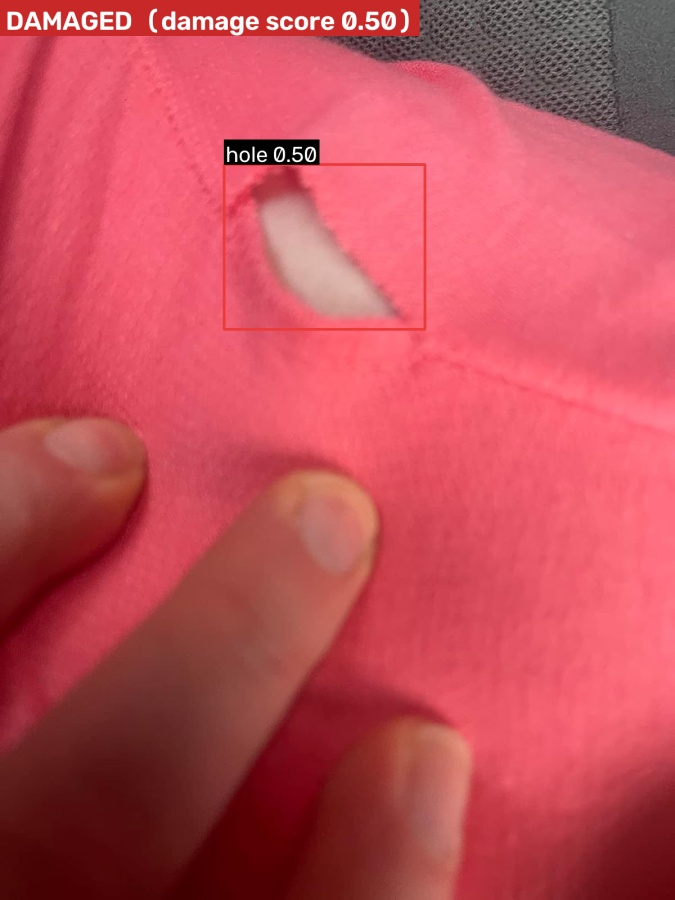

── 938674235f11_1.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ████████████░░░░░░░░ 0.60  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.60 | locator 0.39
   Regions marked : 2   (Damage found (2 region(s)).)


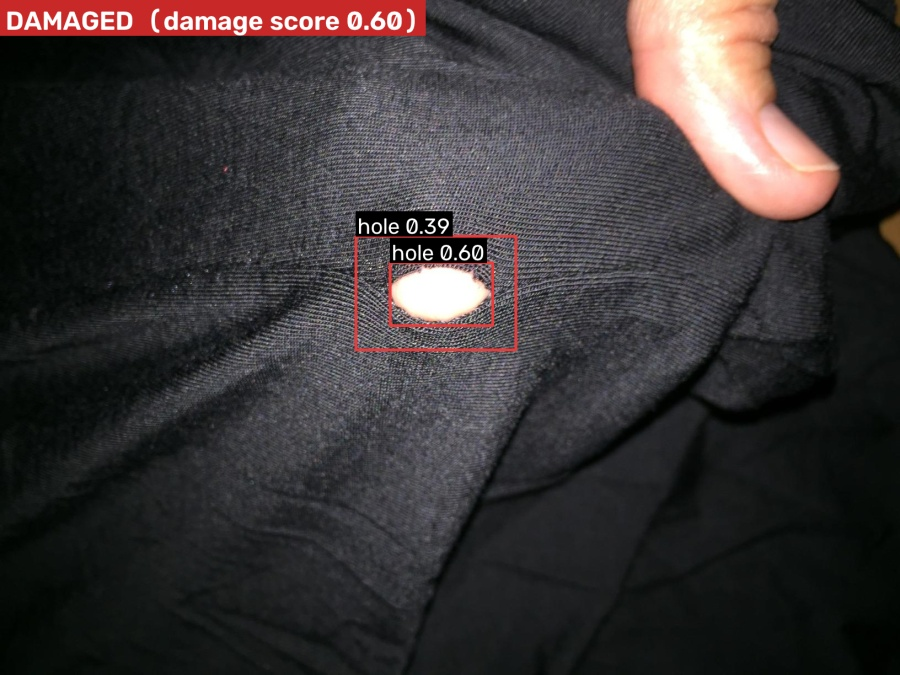

── a194f3d45b70_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ███████████████░░░░░ 0.74  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.40 | locator 0.74
   Regions marked : 3   (Damage found (3 region(s)).)


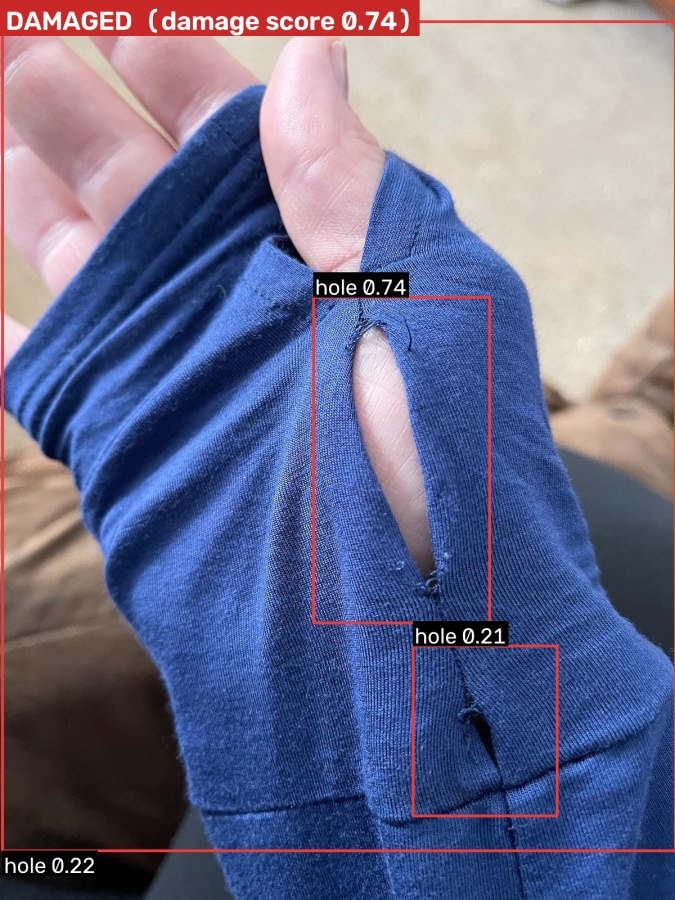

── a30fe2765eb7_1.jpg
   Classification : UNSURE (needs a closer photo)
   Defect types   : none
   hole   score   : █████░░░░░░░░░░░░░░░ 0.27  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.17 | locator 0.27
   Regions marked : 2   (Weak signs of damage. A closer, well-lit photo of the damaged area would help.)


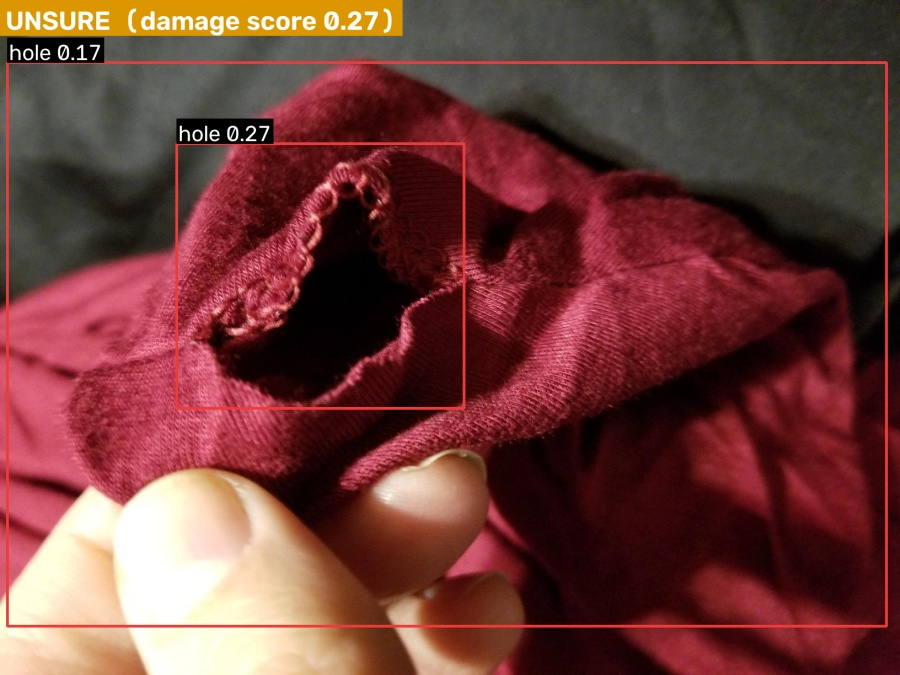

── b6c36aa89924_0.jpg
   Classification : UNSURE (needs a closer photo)
   Defect types   : none
   hole   score   : ███████░░░░░░░░░░░░░ 0.36  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.17 | locator 0.36
   Regions marked : 3   (Weak signs of damage. A closer, well-lit photo of the damaged area would help.)


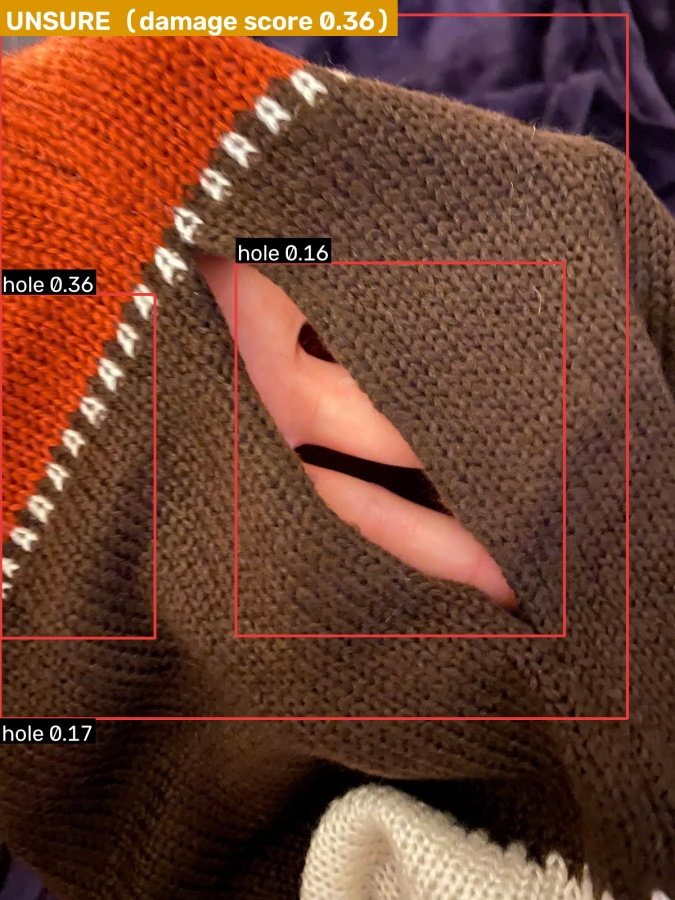

── c0129fcf6e0c_0.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ███████████████░░░░░ 0.75  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.31 | locator 0.75
   Regions marked : 4   (Damage found (4 region(s)).)


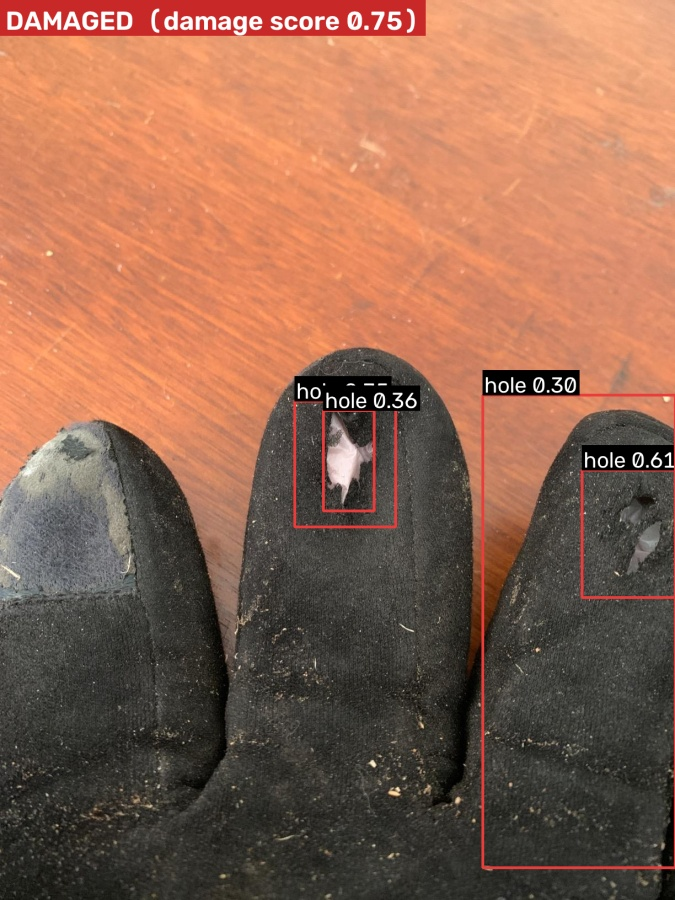

── c58c98a20b1d_1.jpg
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : █████████████████░░░ 0.84  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.84 | locator 0.56
   Regions marked : 3   (Damage found (3 region(s)).)


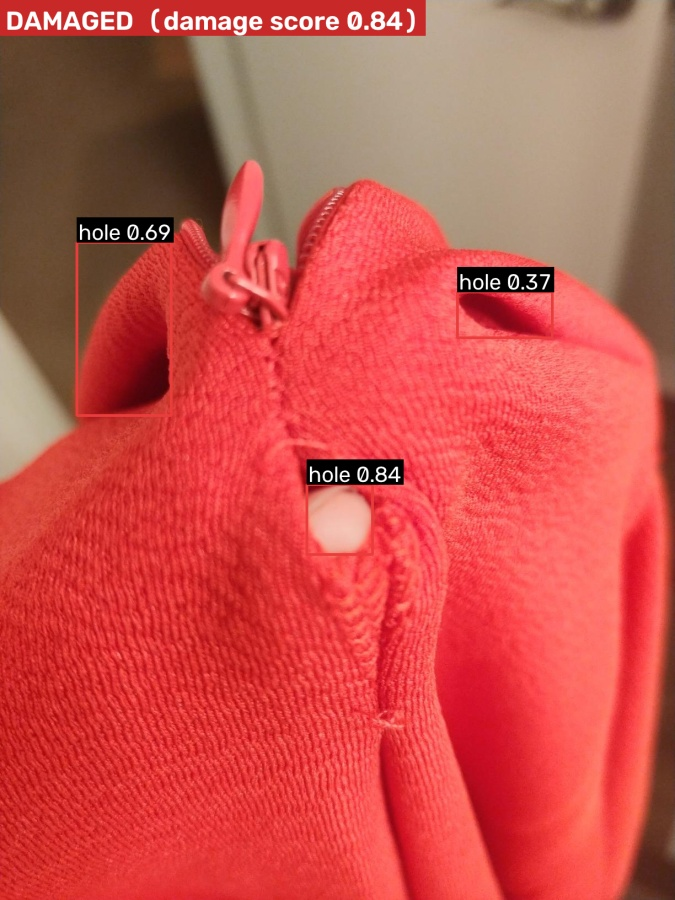

── fdc02c222f1e_0.jpg
   Classification : UNSURE (needs a closer photo)
   Defect types   : none
   hole   score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.00 | locator 0.00 | second opinion 0.60
   Regions marked : 1   (The second-opinion model sees possible damage that the main models missed. A closer, well-lit photo of the marked area would help.)


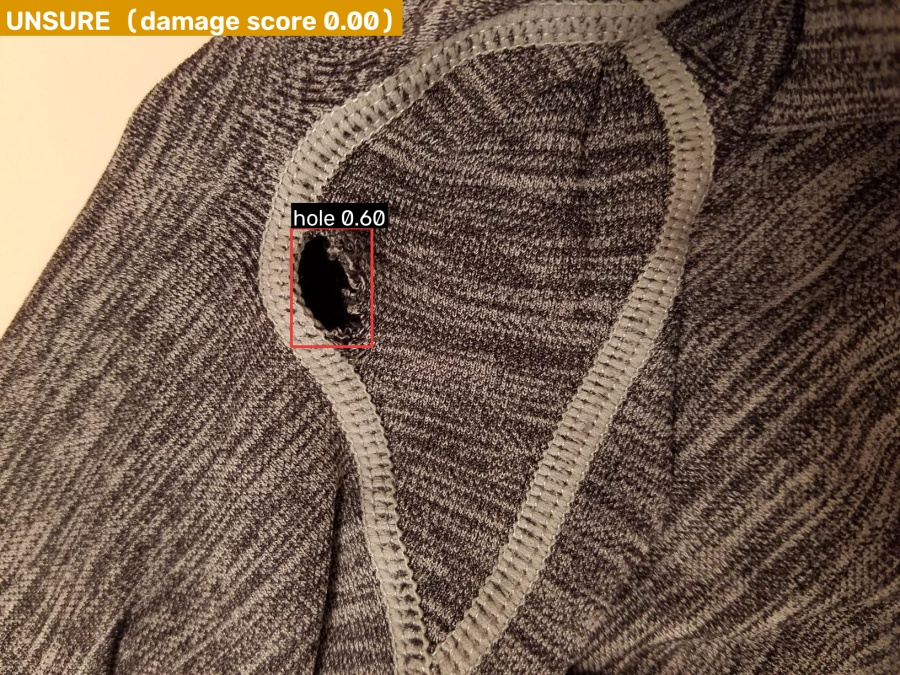

── Screenshot 2026-10-29 132233.png
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ███████████░░░░░░░░░ 0.56  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.51 | locator 0.56
   Regions marked : 7   (Damage found (7 region(s)).)


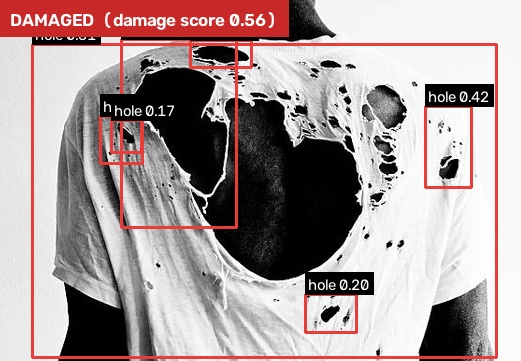

── Screenshot 2026-10-29 185353.png
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : ███████████░░░░░░░░░ 0.53  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.19 | locator 0.53
   Regions marked : 2   (Damage found (2 region(s)).)


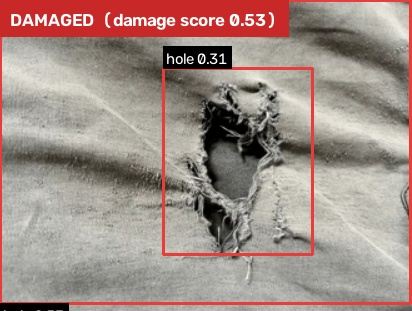

── Screenshot 2026-10-29 185610.png
   Classification : DAMAGED
   Defect types   : hole
   hole   score   : █████████████░░░░░░░ 0.67  <- above threshold
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.00 | locator 0.67
   Regions marked : 1   (Damage found (1 region(s)).)


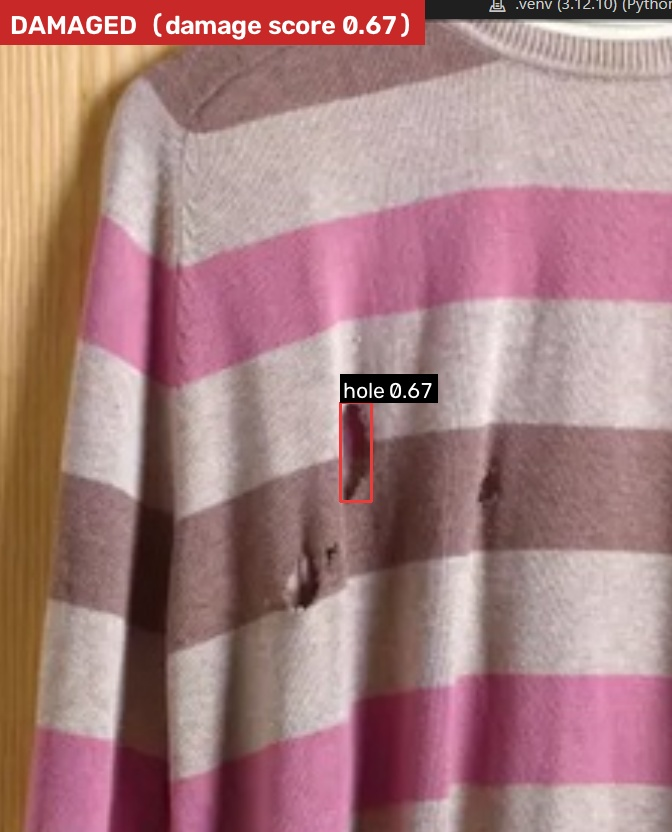

── Screenshot 2026-10-29 185951.png
   Classification : DAMAGED
   Defect types   : stain
   hole   score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   stain  score   : █████████░░░░░░░░░░░ 0.47  <- above threshold
   Model scores   : detector 0.22 | locator 0.47
   Regions marked : 6   (Damage found (6 region(s)).)


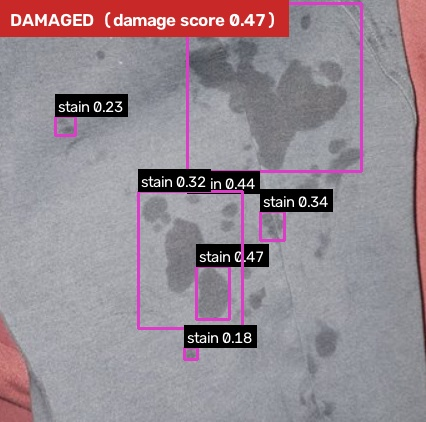

── WhatsApp Image 2026-10-29 at 16.37.34(1).jpeg
   Classification : UNSURE (needs a closer photo)
   Defect types   : none
   hole   score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   stain  score   : ░░░░░░░░░░░░░░░░░░░░ 0.00
   Model scores   : detector 0.00 | locator 0.00 | second opinion 0.53
   Regions marked : 1   (The second-opinion model sees possible damage that the main models missed. A closer, well-lit photo of the marked area would help.)


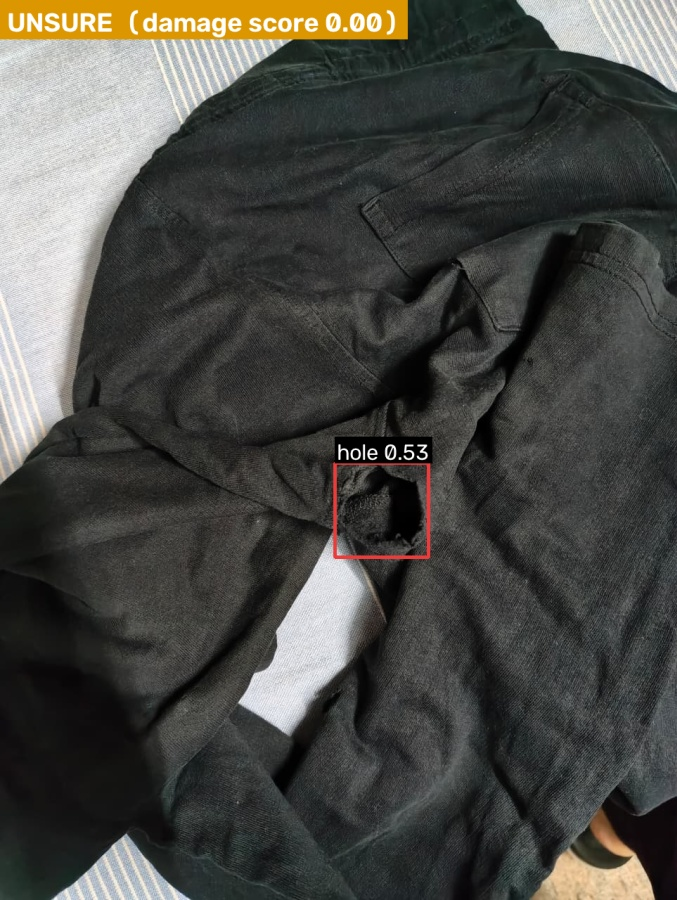

In [49]:
# Cell 5: check every photo in CV/demo_photos (including earlier uploads).
# If the upload cell shows no pictures in your editor, run this cell instead.
folder = CV_DIR / "demo_photos"
folder.mkdir(exist_ok=True)
photos = sorted(p for p in folder.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})
if not photos:
    print(f"No photos yet. Put some in {folder} and run this cell again.")
for p in photos:
    check(load_bytes(p.read_bytes()), p.name)

In [50]:
# Optional: try different thresholds, then re-run cell 4 or 5
predictor.damage_conf = 0.20   # photo counts as damaged at or above this score
predictor.unsure_conf = 0.15   # between this and damage_conf: unsure
predictor.region_conf = 0.15   # locator regions shown at or above this score